In [ ]:
!pip install pyod --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pd.set_option('display.max_columns', 50)

print("Libraries ready.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 418.8/418.8 kB 6.2 MB/s eta 0:00:00
Libraries ready.


In [ ]:
from google.colab import files

print("Upload logon.csv, device.csv, file.csv and insiders.csv:")
uploaded = files.upload()

print("Files uploaded:")
print(list(uploaded.keys()))

Upload logon.csv, device.csv, file.csv and insiders.csv:


Saving device.csv to device (1).csv
Saving file.csv to file (1).csv
Saving insiders.csv to insiders (1).csv
Saving logon.csv to logon (1).csv
Files uploaded:
['device (1).csv', 'file (1).csv', 'insiders (1).csv', 'logon (1).csv']


In [ ]:
logon = pd.read_csv('/content/logon.csv')
device = pd.read_csv('/content/device.csv')
file = pd.read_csv('/content/file.csv')
insiders = pd.read_csv('/content/insiders.csv')

print("logon:", logon.shape)
print("device:", device.shape)
print("file:", file.shape)
print("insiders:", insiders.shape)

display(logon.head())

logon: (854859, 5)
device: (405380, 5)
file: (445581, 6)
insiders: (191, 6)


,id,date,user,pc,activity
0,{X1D9-S0ES98JV-5357PWMI},01/02/2010 06:49:00,NGF0157,PC-6056,Logon
1,{G2B3-L6EJ61GT-2222RKSO},01/02/2010 06:50:00,LRR0148,PC-4275,Logon
2,{U6Q3-U0WE70UA-3770UREL},01/02/2010 06:53:04,LRR0148,PC-4124,Logon
3,{I0N5-R7NA26TG-6263KNGM},01/02/2010 07:00:00,IRM0931,PC-7188,Logon
4,{D1S0-N6FH62BT-5398KANK},01/02/2010 07:00:00,MOH0273,PC-6699,Logon


In [ ]:
logon['date'] = pd.to_datetime(logon['date'])
device['date'] = pd.to_datetime(device['date'])

print("Logon date range:")
print(logon['date'].min(), "to", logon['date'].max())

print("Unique users:", logon['user'].nunique())

Logon date range:
2010-01-02 06:49:00 to 2011-05-17 06:43:35
Unique users: 1000


In [ ]:
malicious_users = set(insiders['user'].unique())

print("Number of known malicious users:", len(malicious_users))
display(insiders.head())

Number of known malicious users: 191


,dataset,scenario,details,user,start,end
0,2.0,1,r2.csv,ONS0995,3/6/2010 1:41:56,3/20/2010 8:10:12
1,3.1,1,r3.1-1.csv,CSF0929,07/01/2010 01:24:58,07/16/2010 06:52:00
2,3.1,2,r3.1-2.csv,CCH0959,08/02/2010 10:34:31,09/30/2010 15:04:03
3,3.2,1,r3.2-1.csv,RCW0822,09/29/2010 21:10:27,10/15/2010 06:34:52
4,3.2,2,r3.2-2.csv,JCE0258,07/12/2010 08:16:02,09/03/2010 16:16:29


In [ ]:
# Make sure date is actually datetime
logon['date'] = pd.to_datetime(logon['date'], errors='coerce')

# Create day and hour columns
logon['day'] = logon['date'].dt.date
logon['hour'] = logon['date'].dt.hour

# Create daily logon behavior features
logon_feats = logon.groupby(['user', 'day']).agg(
    logon_count=('activity', lambda x: (x == 'Logon').sum()),
    logoff_count=('activity', lambda x: (x == 'Logoff').sum()),
    first_logon_hour=('hour', 'min'),
    last_logon_hour=('hour', 'max'),
    n_distinct_pcs=('pc', 'nunique')
).reset_index()

# Detect logins outside normal working hours
logon_feats['offhours_logon'] = (
    (logon_feats['first_logon_hour'] < 6) |
    (logon_feats['last_logon_hour'] > 20)
).astype(int)

print("Logon features:", logon_feats.shape)
display(logon_feats.head())

Logon features: (330452, 8)


,user,day,logon_count,logoff_count,first_logon_hour,last_logon_hour,n_distinct_pcs,offhours_logon
0,AAE0190,2010-01-04,1,1,8,18,1,0
1,AAE0190,2010-01-05,1,1,8,18,1,0
2,AAE0190,2010-01-06,1,1,8,18,1,0
3,AAE0190,2010-01-07,1,1,8,18,1,0
4,AAE0190,2010-01-08,1,1,8,18,1,0


In [ ]:
device['date'] = pd.to_datetime(device['date'], errors='coerce')

# Create day column
device['day'] = device['date'].dt.date

# Create daily device behavior features
device_feats = device.groupby(['user', 'day']).agg(
    device_connects=('activity', lambda x: (x == 'Connect').sum()),
    device_disconnects=('activity', lambda x: (x == 'Disconnect').sum())
).reset_index()

print("Device features:", device_feats.shape)
display(device_feats.head())

Device features: (55717, 4)


,user,day,device_connects,device_disconnects
0,AAF0535,2010-01-05,2,2
1,AAF0535,2010-01-06,1,1
2,AAF0535,2010-01-07,2,2
3,AAF0535,2010-01-08,4,4
4,AAF0535,2010-01-11,1,1


In [ ]:
features = logon_feats.merge(
    device_feats,
    on=['user', 'day'],
    how='left'
)

features[['device_connects', 'device_disconnects']] = (
    features[['device_connects', 'device_disconnects']].fillna(0)
)

features['is_malicious_user'] = (
    features['user'].isin(malicious_users)
).astype(int)

print("Final feature shape:", features.shape)
print(
    "Malicious user-days:",
    features['is_malicious_user'].sum(),
    "out of",
    len(features)
)

display(features.head())

Final feature shape: (330452, 11)
Malicious user-days: 15450 out of 330452


,user,day,logon_count,logoff_count,first_logon_hour,last_logon_hour,n_distinct_pcs,offhours_logon,device_connects,device_disconnects,is_malicious_user
0,AAE0190,2010-01-04,1,1,8,18,1,0,0.0,0.0,0
1,AAE0190,2010-01-05,1,1,8,18,1,0,0.0,0.0,0
2,AAE0190,2010-01-06,1,1,8,18,1,0,0.0,0.0,0
3,AAE0190,2010-01-07,1,1,8,18,1,0,0.0,0.0,0
4,AAE0190,2010-01-08,1,1,8,18,1,0,0.0,0.0,0


In [ ]:
features.to_csv(
    '/content/sentinelai_features.csv',
    index=False
)

print("Day 1 checkpoint saved:")
print("/content/sentinelai_features.csv")

Day 1 checkpoint saved:
/content/sentinelai_features.csv


In [ ]:
feature_cols = [
    'logon_count',
    'logoff_count',
    'first_logon_hour',
    'last_logon_hour',
    'n_distinct_pcs',
    'offhours_logon',
    'device_connects',
    'device_disconnects'
]

X = features[feature_cols].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature matrix:", X.shape)

display(X.describe())

Feature matrix: (330452, 8)


,logon_count,logoff_count,first_logon_hour,last_logon_hour,n_distinct_pcs,offhours_logon,device_connects,device_disconnects
count,330452.000000,330452.000000,330452.000000,330452.000000,330452.000000,330452.000000,330452.000000,330452.000000
mean,1.424083,1.162856,7.515845,17.314490,1.151943,0.080069,0.615336,0.611408
std,0.795866,0.652273,1.245268,1.650583,0.642662,0.271401,1.858010,1.849726
min,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,7.000000,16.000000,1.000000,0.000000,0.000000,0.000000
50%,1.000000,1.000000,8.000000,17.000000,1.000000,0.000000,0.000000,0.000000
75%,2.000000,1.000000,8.000000,18.000000,1.000000,0.000000,0.000000,0.000000
max,9.000000,8.000000,19.000000,23.000000,7.000000,1.000000,14.000000,14.000000


In [ ]:
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

iso_forest.fit(X_scaled)

features['anomaly_score'] = (
    -iso_forest.decision_function(X_scaled)
)

features['is_flagged'] = (
    iso_forest.predict(X_scaled) == -1
).astype(int)

display(
    features[['anomaly_score', 'is_flagged']].describe()
)

,anomaly_score,is_flagged
count,330452.000000,330452.000000
mean,-0.213883,0.049995
std,0.097687,0.217935
min,-0.293044,0.000000
25%,-0.283074,0.000000
50%,-0.245806,0.000000
75%,-0.178476,0.000000
max,0.181671,1.000000


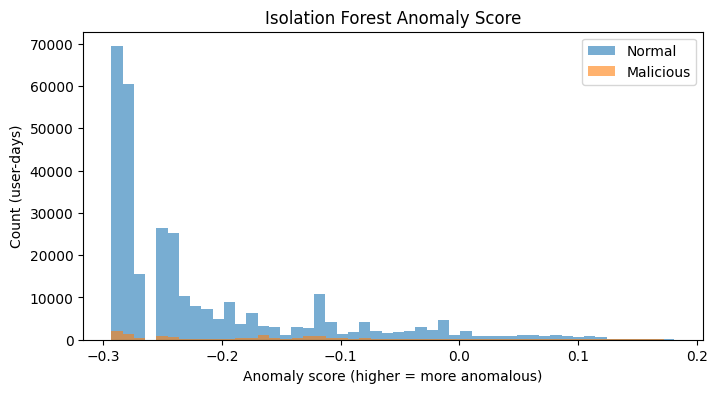

In [ ]:
plt.figure(figsize=(8, 4))

plt.hist(
    features.loc[
        features['is_malicious_user'] == 0,
        'anomaly_score'
    ],
    bins=50,
    alpha=0.6,
    label='Normal'
)

plt.hist(
    features.loc[
        features['is_malicious_user'] == 1,
        'anomaly_score'
    ],
    bins=50,
    alpha=0.6,
    label='Malicious'
)

plt.xlabel('Anomaly score (higher = more anomalous)')
plt.ylabel('Count (user-days)')
plt.title('Isolation Forest Anomaly Score')
plt.legend()
plt.show()

In [ ]:
y_true = features['is_malicious_user']
y_pred = features['is_flagged']

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=['Normal', 'Malicious']
    )
)

print(
    "\nROC-AUC:",
    roc_auc_score(
        y_true,
        features['anomaly_score']
    )
)

Confusion Matrix:
[[300838  14164]
 [ 13093   2357]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.96      0.96    315002
   Malicious       0.14      0.15      0.15     15450

    accuracy                           0.92    330452
   macro avg       0.55      0.55      0.55    330452
weighted avg       0.92      0.92      0.92    330452


ROC-AUC: 0.6677027941611261


In [ ]:
def risk_tier(score, p50, p90):
    if score >= p90:
        return 'High'
    elif score >= p50:
        return 'Medium'
    else:
        return 'Low'


p50 = features['anomaly_score'].quantile(0.50)
p90 = features['anomaly_score'].quantile(0.90)

features['risk_tier'] = features['anomaly_score'].apply(
    lambda score: risk_tier(score, p50, p90)
)

print("Risk distribution:")
print(features['risk_tier'].value_counts())

display(
    features[
        [
            'user',
            'day',
            'anomaly_score',
            'risk_tier',
            'is_malicious_user'
        ]
    ]
    .sort_values(
        'anomaly_score',
        ascending=False
    )
    .head(15)
)

Risk distribution:
risk_tier
Low       160337
Medium    136983
High       33132
Name: count, dtype: int64


,user,day,anomaly_score,risk_tier,is_malicious_user
44264,BSS0369,2010-09-30,0.181671,High,1
222816,MPM0220,2010-04-28,0.181119,High,1
143788,IBB0359,2010-02-23,0.181119,High,0
144039,IBB0359,2011-02-17,0.181119,High,0
11253,AJF0370,2010-09-13,0.181119,High,0
222912,MPM0220,2010-09-13,0.181119,High,1
11378,AJF0370,2011-02-28,0.180843,High,0
11397,AJF0370,2011-03-24,0.180843,High,0
11094,AJF0370,2010-02-10,0.180843,High,0
11372,AJF0370,2011-02-21,0.180843,High,0


In [ ]:
features.to_csv(
    '/content/sentinelai_results.csv',
    index=False
)

print("DONE!")
print("Final file:")
print("/content/sentinelai_results.csv")

DONE!
Final file:
/content/sentinelai_results.csv
